# Genetic Association Distributions — common vs rare diseases

Standalone re-creation of four figures originally produced in
`disease_definition_pipeline/01_build_disease_def.ipynb`:

1. **Distribution of OpenTargets `avg_genetic_association_score` > 0** (common vs rare) — histogram
2. **Source of Genetic Associations for Common Diseases** — horizontal barplot
3. **Source of Genetic Associations for Rare Diseases** — horizontal barplot
4. **Source of Open Targets Genetic Association Scores** — grouped barplot (common vs rare)

The pipeline is reproduced faithfully from the source notebook. **This notebook is
self-contained**: all raw inputs (Open Targets + MONDO tables and the two manual
relabel spreadsheets) live in the local `./data` directory, so no external config
or shared drive is needed.

In [1]:
import os

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Deterministic down-sampling for the histogram (see Plot 1).
np.random.seed(0)

DATA = "../data"
assert os.path.isdir(DATA), f"expected ../data next to the notebook; cwd={os.getcwd()}"


def find_data(*tokens):
    # Resolve the single file in ../data whose name contains all given tokens.
    # Inputs are matched by distinctive substrings rather than hard-coded
    # filenames, so the notebook keeps working if the data files are renamed.
    # Errors clearly if zero or multiple files match.
    matches = sorted(
        f for f in os.listdir(DATA)
        if all(t.lower() in f.lower() for t in tokens)
    )
    if len(matches) != 1:
        raise FileNotFoundError(
            f"expected exactly one file in ../data matching {tokens}, found {matches}"
        )
    return os.path.join(DATA, matches[0])


print("data dir:", os.path.abspath(DATA))
print("files:", sorted(os.listdir(DATA)))

data dir: /Users/kwfh644/GitHub/dis2vec-public/data
files: ['.DS_Store', '.claude', 'Dis2Vec_map_dis_vec_clust_UMAP.html', 'Dis2Vec_map_rare_UMAP.html', 'MONDO_rare_common.parquet.gzip', 'UPNA-DDAL_epochs_2__embeddings_node2vec_MechDist_dimensions_128_WalkLength_10_NumWalks_100.h5', 'common_rare_OT_mondo.xlsx', 'dis2vec_all_preds.parquet.gzip', 'dis2vec_clust.xlsx', 'disease_id_names.csv', 'embeddings_node2vec_MechDist_dimensions_128_WalkLength_10_NumWalks_100.pickle', 'go_bp_dist_matrix.parquet.gzip', 'hpo_dist_matrix.parquet.gzip', 'manual_curation_common_false_positive.xlsx', 'opentargets-diseases.csv', 'ot_assoc_lookup.csv', 'ot_gene_association_by_datasource.csv']


## 1. Load Open Targets diseases and normalise IDs

In [2]:
# Open Targets disease table (source nb cell 13)
ot_dis_df = pd.read_csv(find_data("opentargets-diseases"))

mask = ot_dis_df["MONDO_id"].fillna("").str.contains("_")
ot_dis_df.loc[mask, "MONDO_id"] = ot_dis_df.loc[mask, "MONDO_id"].str.replace("_", ":")

# one Orphanet id per record
mask = ~ot_dis_df["Orphanet_id"].isnull()
ot_dis_df.loc[mask, "orphanet_disease_id"] = (
    ot_dis_df.loc[mask, "Orphanet_id"].str.replace(":", "_").apply(lambda x: x.split("_")[-1]).astype(int)
)
print(len(ot_dis_df), "diseases")

25246 diseases


## 2. Load disease–gene associations (per-datasource scores)

In [3]:
# Per-datasource genetic-association evidence (source nb cell 15).
# Also reused directly for the "source of associations" barplots below.
ot_gene_assoc_all_df = pd.read_csv(find_data("gene_association_by_datasource"))

# Pivot datasources into columns (gives us e.g. `ot_genetics_portal` score column).
ot_gene_assoc_pivot_df = (
    ot_gene_assoc_all_df
    .pivot(index=["diseaseid", "targetid"], columns=["datasourceid"], values=["score", "evidencecount"])
    .reset_index()
)
ot_gene_assoc_pivot_df.columns = (
    [c[0] for c in ot_gene_assoc_pivot_df.columns[0:2]]
    + [" ".join(c).replace("score ", "") for c in ot_gene_assoc_pivot_df.columns[2:]]
)
ot_gene_assoc_pivot_df = ot_gene_assoc_pivot_df.rename(columns={"targetid": "gene_ensembl_id"})
print(ot_gene_assoc_all_df.shape, "->", ot_gene_assoc_pivot_df.shape)

(1419414, 6) -> (1141122, 20)


In [4]:
# Overall disease-gene lookup with aggregate scores (source nb cell 16).
ot_dis_gene_df = pd.read_csv(find_data("assoc_lookup"))
ot_dis_gene_df = ot_dis_gene_df.rename(columns={"targetid": "gene_ensembl_id", "approvedsymbol": "gene_symbol"})

ot_dis_gene_df = pd.merge(ot_dis_gene_df, ot_gene_assoc_pivot_df, on=["diseaseid", "gene_ensembl_id"], how="left")

ot_dis_gene_df = pd.merge(
    ot_dis_df[["id", "code", "description", "name", "obsoleteterms",
               "is_cancer_or_tumor", "MONDO_id", "Orphanet_id", "OMIM_id", "orphanet_disease_id"]]
        .rename(columns={"id": "diseaseid"}),
    ot_dis_gene_df,
    on="diseaseid",
)
print(len(ot_dis_gene_df), "disease-gene rows")

7994180 disease-gene rows


## 3. Attach MONDO rare / common labels

In [5]:
# MONDO rare/common/obsolete flags (source nb cell 94).
mondo_df = pd.read_parquet(find_data("MONDO", "rare_common", ".parquet"))
mondo_df["rare"] = mondo_df["rare"].str.replace("NA", "NA: Cant Assign Using MONDO")
mondo_df["MONDO_id"] = mondo_df["id"].apply(lambda x: x.split("/")[-1].replace("_", ":"))

# Merge labels onto the OT disease table (source nb cell 98).
ot_dis_mondo_df = pd.merge(ot_dis_df, mondo_df.drop(columns=["id"]), on="MONDO_id", how="left")
ot_dis_mondo_df["rare"] = ot_dis_mondo_df["rare"].fillna("NA: OT missing MONDO")
print(ot_dis_mondo_df["rare"].value_counts().to_dict())

{'NA: OT missing MONDO': 13511, 'rare': 9017, 'common': 2657, 'NA: Cant Assign Using MONDO': 61}


## 4. Aggregate per-disease scores → `plot_df`

In [6]:
col_ot_score = "genetic_association_score"
score_min = 0

# Per-disease aggregates over genes with a genetic-association score (source nb cell 102).
ot_dis_gene_grp_df = (
    ot_dis_gene_df[ot_dis_gene_df[col_ot_score] > score_min]
    .groupby(["diseaseid"])
    .agg(
        dis_gene_count=("gene_ensembl_id", np.size),
        overall_score=("overall_score", np.mean),
        avg_genetic_association_score=("genetic_association_score", np.mean),
        avg_somatic_mutation_score=("somatic_mutation_score", np.mean),
        avg_overall_score=("overall_score", np.mean),
        avg_ot_genetics_portal=("ot_genetics_portal", np.mean),
    )
    .reset_index()
)

# Join aggregates to labelled diseases, drop cancers (source nb cell 105).
ot_dis_mondo_gene_grp_df = (
    pd.merge(ot_dis_mondo_df.rename(columns={"id": "diseaseid"}), ot_dis_gene_grp_df, on="diseaseid", how="left")
    .sort_values(by="dis_gene_count", ascending=False)
    .reset_index(drop=True)
)
ot_dis_mondo_gene_grp_df = ot_dis_mondo_gene_grp_df[
    ~(
        ot_dis_mondo_gene_grp_df["name"].str.contains("cancer", na=False)
        | ot_dis_mondo_gene_grp_df["description"].astype(str).str.contains("cancer")
    )
]
_cols = ["dis_gene_count", "overall_score", "avg_genetic_association_score",
         "avg_somatic_mutation_score", "avg_overall_score", "avg_ot_genetics_portal"]
ot_dis_mondo_gene_grp_df.loc[:, _cols] = ot_dis_mondo_gene_grp_df.loc[:, _cols].fillna(0)

### Manual rare/common relabelling

Two curated spreadsheets correct MONDO's rare/common labels for specific diseases
(source nb cells 111–114). These are load-bearing for the exact common/rare counts
shown in the figure titles.

In [7]:
# Round 1: diseases MONDO calls "common" that are actually rare (source nb cells 111-112).
manual_curation_common_false_positive_df = pd.read_excel(find_data("common_false_positive"))
manual_curation_common_false_positive_df = manual_curation_common_false_positive_df[
    (manual_curation_common_false_positive_df["rare"] == "common")
    & (manual_curation_common_false_positive_df["rare_reclass"] == "rare")
]
mask_common_FP = ot_dis_mondo_gene_grp_df["diseaseid"].isin(
    manual_curation_common_false_positive_df["diseaseid"]
)
ot_dis_mondo_gene_grp_df.loc[mask_common_FP, "rare"] = "rare"

# Round 2: diseases manually relabelled back to common (source nb cells 113-114).
manual_fix_2nd_round_df = pd.read_excel(find_data("common_rare_OT_mondo", ".xlsx"))
disease_id_to_common = manual_fix_2nd_round_df[
    manual_fix_2nd_round_df["Babak relabel"] == "common"
]["OT diseaseid"].unique()
mask = ot_dis_mondo_gene_grp_df["diseaseid"].isin(disease_id_to_common)
ot_dis_mondo_gene_grp_df.loc[mask, "rare"] = "common"

print(ot_dis_mondo_gene_grp_df[
    (ot_dis_mondo_gene_grp_df["obsolete"] == 0)
    & (ot_dis_mondo_gene_grp_df["avg_" + col_ot_score] > 0)
]["rare"].value_counts().to_dict())

{'rare': 5756, 'common': 1235, 'NA: Cant Assign Using MONDO': 10}


In [8]:
# Common + rare diseases within a gene-count cap (source nb cell 126).
max_dis_gene_assoc = 30000

common_df = ot_dis_mondo_gene_grp_df[
    (ot_dis_mondo_gene_grp_df["dis_gene_count"] < max_dis_gene_assoc)
    & (ot_dis_mondo_gene_grp_df["rare"] == "common")
    & (ot_dis_mondo_gene_grp_df["obsolete"] == 0)
]
sample_rare_df = ot_dis_mondo_gene_grp_df[
    (ot_dis_mondo_gene_grp_df["dis_gene_count"] < max_dis_gene_assoc)
    & (ot_dis_mondo_gene_grp_df["rare"] == "rare")
    & (ot_dis_mondo_gene_grp_df["obsolete"] == 0)
]

plot_df = pd.concat([common_df, sample_rare_df])
plot_df = plot_df[plot_df["dis_gene_count"] < max_dis_gene_assoc]
plot_df["dis_gene_count + 1"] = plot_df["dis_gene_count"] + 1
print("plot_df:", plot_df["rare"].value_counts().to_dict())

plot_df: {'rare': 8659, 'common': 2296}


## Plot 1 — Distribution of `avg_genetic_association_score` > 0 (common vs rare)

Rare diseases are down-sampled to the number of common diseases so the two
distributions are directly comparable (source nb cell 143).

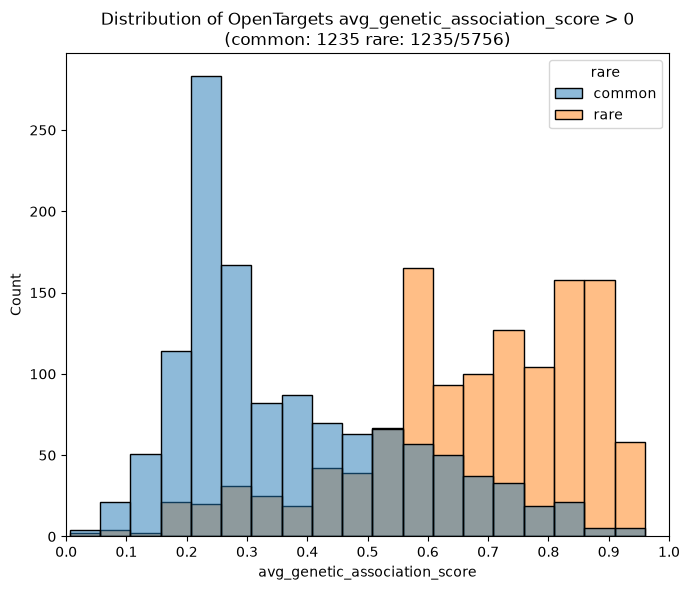

In [9]:
fig, ax = plt.subplots(figsize=(7, 6), dpi=100)

plost_score_common_df = plot_df[(plot_df["rare"] == "common") & (plot_df["avg_" + col_ot_score] > 0)]
plost_score_rare_df = plot_df[(plot_df["rare"] == "rare") & (plot_df["avg_" + col_ot_score] > 0)]

sample_size = min(len(plost_score_rare_df), len(plost_score_common_df))
plost_score_rare_df = plost_score_rare_df.sample(sample_size)

plot_score_df = pd.concat([plost_score_common_df, plost_score_rare_df])

sns.histplot(plot_score_df, binwidth=0.05, x="avg_" + col_ot_score, hue="rare", ax=ax)
ax.set_title(
    "Distribution of OpenTargets {} > 0\n(common: {} rare: {}/{})".format(
        "avg_" + col_ot_score,
        len(plost_score_common_df),
        len(plost_score_rare_df),
        len(plot_df[(plot_df["rare"] == "rare") & (plot_df["avg_" + col_ot_score] > 0)]),
    )
)
ax.set_xticks(np.arange(0, 1.01, 0.1))
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()

## Plots 2–4 — Source of genetic associations

Break the disease–gene associations down by Open Targets data source
(GWAS, ClinVar, ClinGen, …) for common vs rare diseases (source nb cells 145–154).

In [10]:
# Diseases (common & rare) with a genetic-association score (source nb cell 145).
common_rare_OT_mondo_df = plot_df[(plot_df["obsolete"] == 0) & (plot_df["avg_genetic_association_score"] > 0)]

# Human-readable labels for each Open Targets datasource (source nb cell 149).
genetic_database_df = pd.DataFrame([
    ("ot_genetics_portal", "GWAS"),
    ("eva", "ClinVar"),
    ("clingen", "ClinGen"),
    ("genomics_england", "Genomics England"),
    ("orphanet", "Orphanet"),
    ("gene2phenotype", "Gene2Phenotype"),
    ("gene_burden", "Gene Burden"),
    ("uniprot_variants", "Uniprot Variants"),
    ("uniprot_literature", "Uniprot Literature"),
], columns=["datasourceid", "label"])


def source_breakdown(rare_label):
    # % of associations per datasource for the given rare/common cohort.
    ids = common_rare_OT_mondo_df[common_rare_OT_mondo_df["rare"] == rare_label]["diseaseid"]
    df = (
        ot_gene_assoc_all_df[ot_gene_assoc_all_df["diseaseid"].isin(ids)]
        .groupby("datasourceid")
        .agg(
            count_associations=("targetid", np.size),
            avg_score=("score", "mean"),
            std_score=("score", "std"),
            avg_evidence_count=("evidencecount", "mean"),
            std_evidence_count=("evidencecount", "std"),
        )
        .sort_values(by="count_associations", ascending=False)
        .reset_index()
    )
    df["count_associations perc"] = (
        (df["count_associations"] / df["count_associations"].sum() * 100).round(2)
    )
    return pd.merge(genetic_database_df, df, on="datasourceid")


common_genetic_assoc_source_df = source_breakdown("common")
rare_genetic_assoc_source_df = source_breakdown("rare")
print("common diseases:", (common_rare_OT_mondo_df["rare"] == "common").sum(),
      "| rare diseases:", (common_rare_OT_mondo_df["rare"] == "rare").sum())

common diseases: 1235 | rare diseases: 5756


### Plot 2 — Source of Genetic Associations for Common Diseases

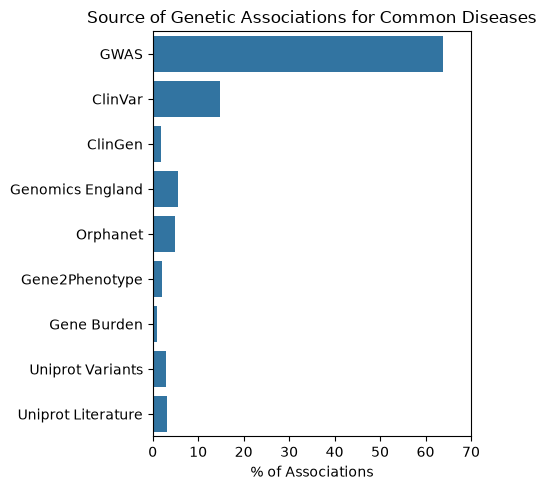

In [11]:
fig, axs = plt.subplots(figsize=(5, 5), dpi=100, facecolor="white")
sns.barplot(common_genetic_assoc_source_df, y="label", x="count_associations perc", ax=axs)
axs.set_title("Source of Genetic Associations for Common Diseases")
axs.set_xlim([0, 70])
axs.set(xlabel="% of Associations", ylabel="")
plt.tight_layout()
plt.show()

### Plot 3 — Source of Genetic Associations for Rare Diseases

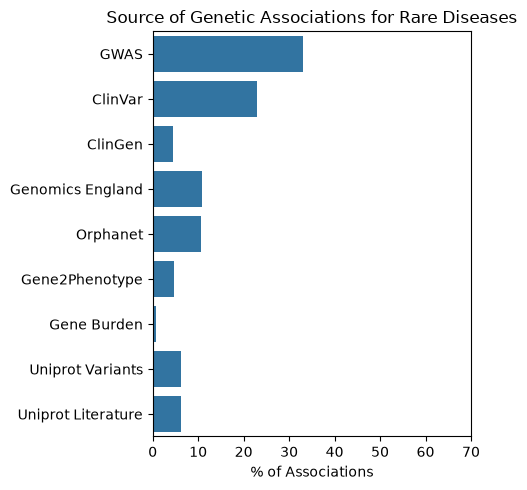

In [12]:
fig, axs = plt.subplots(figsize=(5, 5), dpi=100, facecolor="white")
sns.barplot(rare_genetic_assoc_source_df, y="label", x="count_associations perc", ax=axs)
axs.set_title("Source of Genetic Associations for Rare Diseases")
axs.set_xlim([0, 70])
axs.set(xlabel="% of Associations", ylabel="")
plt.tight_layout()
plt.show()

### Plot 4 — Source of Open Targets Genetic Association Scores (common vs rare)

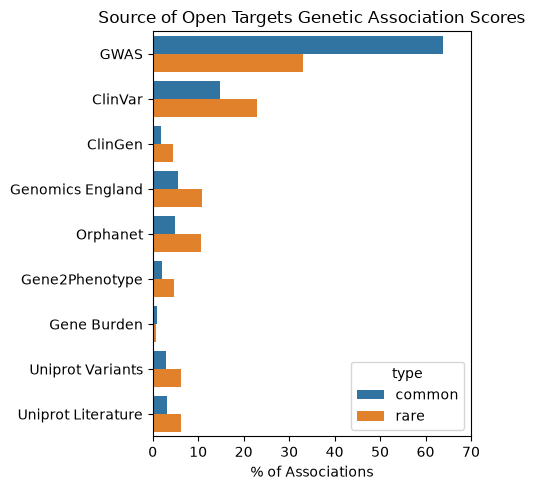

In [13]:
common_genetic_assoc_source_df["type"] = "common"
rare_genetic_assoc_source_df["type"] = "rare"

common_rare_genetic_assoc_source_df = pd.concat(
    [common_genetic_assoc_source_df, rare_genetic_assoc_source_df]
).reset_index(drop=True)

fig, axs = plt.subplots(figsize=(5, 5), dpi=100, facecolor="white")
sns.barplot(common_rare_genetic_assoc_source_df, y="label", x="count_associations perc", hue="type", ax=axs)
axs.set_title("Source of Open Targets Genetic Association Scores")
axs.set_xlim([0, 70])
axs.set(xlabel="% of Associations", ylabel="")
plt.tight_layout()
plt.show()